In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.constants as const

In [2]:
def load_data(path):
    data = np.loadtxt(path, delimiter=',', skiprows=2, dtype=str)
    x = data[0:, 0]  # Assuming the first column is X values
    ch1 = data[0:, 1]  # Assuming the second column is Y values
    ch2 = data[0:, 2]  # Assuming the third column is Y values

    x = x.astype(float)
    ch1 = ch1.astype(float)
    ch2 = ch2.astype(float)

    return x, ch1, ch2

def plot_channel(x, ch1, ch2=None, label1='CH1', label2='CH2', title='Channel Plot'):
    plt.plot(x, ch1, label=label1)
    if ch2 is not None:
        plt.plot(x, ch2, label=label2)
    plt.title(title)
    plt.grid(True)
    plt.legend()

Test plot

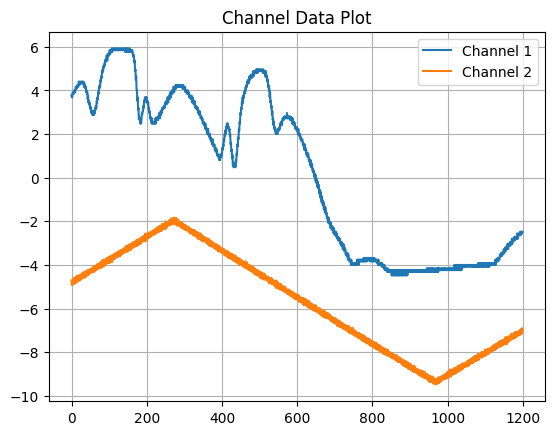

In [3]:
x, ch1, ch2 = load_data('data\\NewFile1.csv')
plot_channel(x, ch1, ch2, label1='Channel 1', label2='Channel 2', title='Channel Data Plot')

In [4]:
def load_data_remove_background(file_1, file_2):
    dataA = np.loadtxt(file_1, delimiter=',', skiprows=2, dtype=str)
    dataB = np.loadtxt(file_2, delimiter=',', skiprows=2, dtype=str)

    x = dataA[0:, 0] 
    ch1a = dataA[0:, 1]  
    ch1b = dataB[0:, 1] 
    ch2 = dataA[0:, 2]

    x = x.astype(float)
    ch1a = ch1a.astype(float)
    ch1b = ch1b.astype(float)
    ch2 = ch2.astype(float)

    return x, ch1a - ch1b, ch2

### Doppler broadened spectrum with background correction

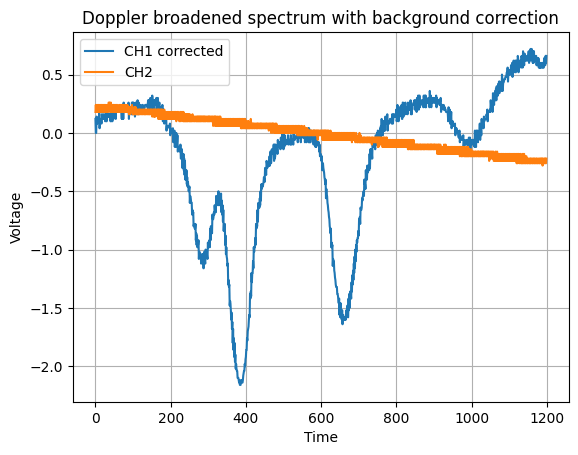

In [5]:
x, ch1_corrected, ch2 = load_data_remove_background('data\\NewFile11.csv', 'data\\NewFile12.csv')

# plot
plt.plot(x, ch1_corrected, label='CH1 corrected')
plt.plot(x, ch2, label='CH2')
plt.xlabel('Time')
plt.ylabel('Voltage')
plt.legend()
plt.title("Doppler broadened spectrum with background correction")
plt.grid(True)
plt.show()

Fit voltage to time

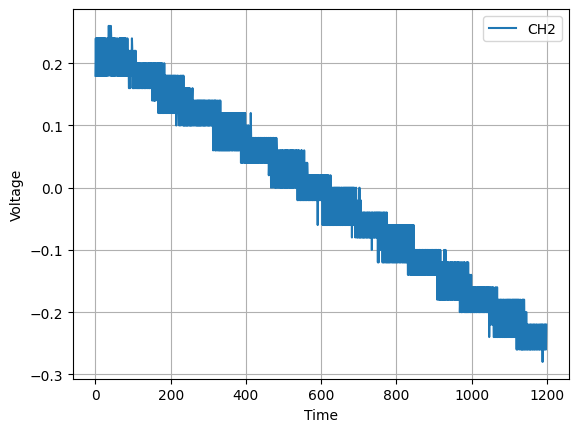

In [6]:
# plot
plt.plot(x, ch2, label='CH2')
plt.xlabel('Time')
plt.ylabel('Voltage')
plt.legend()
plt.grid(True)
plt.show()

In [7]:
# linear fit voltage vs time
def fit_voltage(x, ch2, deg=1):
    ch2_linear = np.polyfit(x, ch2, deg=deg)
    voltage = np.polyval(ch2_linear, x)
    return voltage

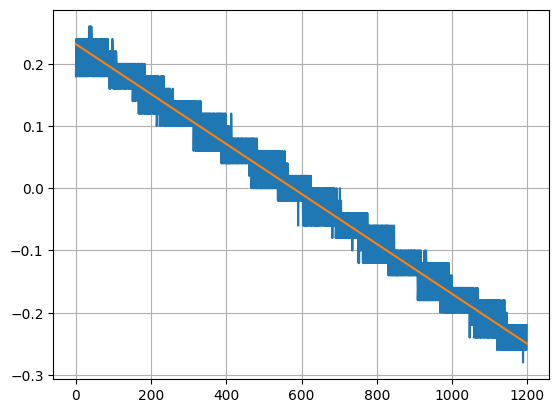

In [8]:
voltage = fit_voltage(x, ch2)

plt.plot(x, ch2, label='CH2')
plt.plot(x, voltage, label='CH2 linear fit')
plt.grid(True)

In [9]:
from scipy.signal import find_peaks

def find_voltage_minima_indices(x, ch1_corrected):
    # Find minima by detecting peaks in the inverted signal
    minima_indices, properties = find_peaks(
        -ch1_corrected,
        prominence=0.2,
        distance=50
    )

    # Show minima from left to right
    minima_indices = minima_indices[np.argsort(x[minima_indices])]
    return minima_indices

In [10]:
minima_indices = find_voltage_minima_indices(x, ch1_corrected)
# find the corresponding voltage frequency sweep values
peak_voltages = voltage[minima_indices]
print("Peak voltages:", peak_voltages)

Peak voltages: [ 0.11648379  0.07715821 -0.03199035 -0.16641964]


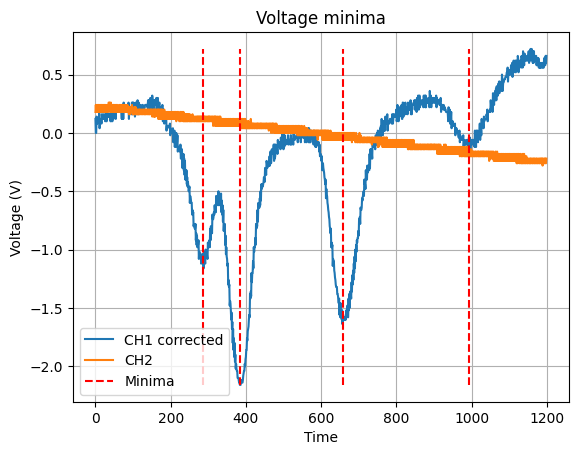

In [11]:
# plot
plot_channel(x, ch1_corrected, ch2, label1='CH1 corrected', label2='CH2', title='Voltage minima')
plt.vlines(x[minima_indices], ymin=np.min(ch1_corrected), ymax=np.max(ch1_corrected), color='r', linestyle='--', label='Minima')
plt.xlabel('Time')
plt.grid(True)
plt.ylabel('Voltage (V)')
plt.legend()
plt.show()

In [12]:
f_peaks = []

In [13]:
# peak 1 freq value (source:https://steck.us/alkalidata/)
peak1freq = 384230.484468 - 2.56300597908 #GHz
peak1freqTHz = peak1freq / 1e3
f_peaks.append(peak1freqTHz)
print(f"Peak 1 frequency: {peak1freqTHz:.6f} THz")

Peak 1 frequency: 384.227921 THz


In [14]:
# peak 2 freq value (source:https://steck.us/alkalidata/)
peak2freq = 384230.406373 - 1.2648885163 #GHz
peak2freqTHz = peak2freq / 1e3
f_peaks.append(peak2freqTHz)
print(f"Peak 2 frequency: {peak2freqTHz:.6f} THz")

Peak 2 frequency: 384.229141 THz


In [15]:
# peak 3 freq value (source:https://steck.us/alkalidata/)
peak3freq = 384230.406373 + 1.7708439228
peak3freqTHz = peak3freq / 1e3
f_peaks.append(peak3freqTHz)
print(f"Peak 3 frequency: {peak3freqTHz:.6f} THz")

Peak 3 frequency: 384.232177 THz


In [16]:
# peak 4 freq value (source:https://steck.us/alkalidata/)
peak4freq = 384230.4844685 + 4.27167663182
peak4freqTHz = peak4freq / 1e3
f_peaks.append(peak4freqTHz)
print(f"Peak 4 frequency: {peak4freqTHz:.6f} THz")

Peak 4 frequency: 384.234756 THz


In [17]:
print(f_peaks)

[384.22792146202096, 384.2291414844837, 384.2321772169228, 384.2347561451318]


Fit frequency to voltage

In [18]:
def fit_freq_to_voltage(f_peaks, peak_voltages, deg=1):
    # Fit a linear function to the frequency vs voltage data
    coeffs = np.polyfit(peak_voltages, f_peaks, deg=deg)
    calibration_func = np.poly1d(coeffs)
    return calibration_func

[384.22792146202096, 384.2291414844837, 384.2321772169228, 384.2347561451318]


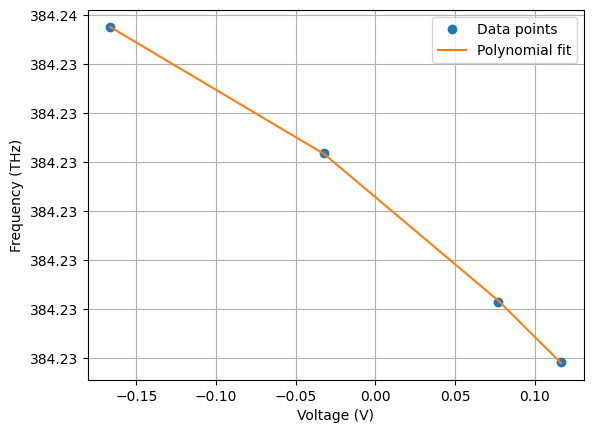

Slope method 2/ linear fit: -0.024159067781568812


In [19]:
# Fit freq to voltage
calibration_func = fit_freq_to_voltage(f_peaks, peak_voltages, deg=2)

print(f_peaks)
fig, ax = plt.subplots()

ax.plot(peak_voltages, f_peaks, 'o', label='Data points')
ax.plot(peak_voltages, calibration_func(peak_voltages), label='Polynomial fit')

ax.set_xlabel('Voltage (V)')
ax.set_ylabel('Frequency (THz)')

ax.yaxis.set_major_formatter( plt.FuncFormatter(lambda x, _: f'{x:.2f}'))

ax.grid(True)
ax.legend()
plt.show()

# print("Slope:", poly_coeffs[0]) 
print("Slope method 2/ linear fit:", (f_peaks[-1] - f_peaks[0]) / (peak_voltages[-1] - peak_voltages[0]))

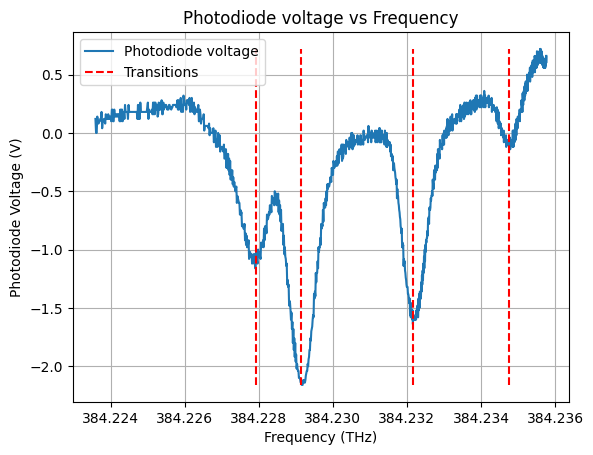

In [20]:
f_range = calibration_func(voltage)

plot_channel(f_range, ch1_corrected, label1='Photodiode voltage', title='Photodiode voltage vs Frequency')
plt.vlines(f_peaks, ymin=np.min(ch1_corrected), ymax=np.max(ch1_corrected), color='r', linestyle='--', label='Transitions')
plt.ticklabel_format(axis='x', style='plain', useOffset=False)
plt.xlabel('Frequency (THz)') # should be 380 THz=e12 at first peak roughly 
plt.ylabel('Photodiode Voltage (V)')
plt.legend()
plt.grid(True)
plt.show()


### Doppler free spectrum

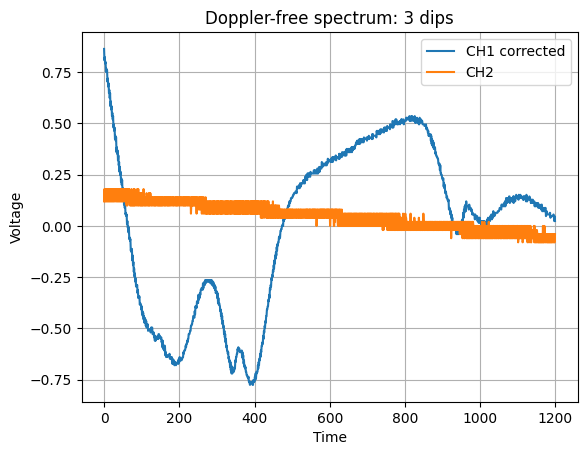

In [21]:
x_df, ch1_corrected_df, ch2_df = load_data_remove_background('data\\NewFile17.csv', 'data\\NewFile18.csv')

# plot
plot_channel(x_df, ch1_corrected_df, ch2_df, label1='CH1 corrected', label2='CH2', title='Doppler-free spectrum: 3 dips')
plt.xlabel('Time')
plt.ylabel('Voltage')
plt.legend()
plt.grid(True)
plt.show()

Fit voltage to time

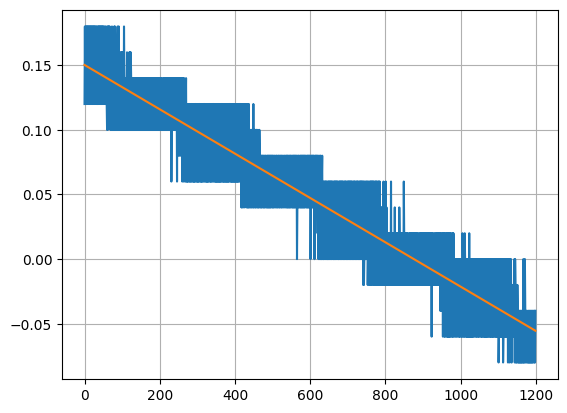

In [22]:
fit_voltage_df = fit_voltage(x_df, ch2_df)

voltage_df = fit_voltage(x_df, ch2_df)

plt.plot(x_df, ch2_df, label='CH2')
plt.grid(True)
plt.plot(x_df, fit_voltage_df, label='CH2 linear fit')

In [23]:
# guess voltage minima since we have peaks within dips
minima_indices_df = [152, 360, 966]
# find the corresponding voltage frequency sweep values
peak_voltages_df = voltage_df[minima_indices_df]
print("Peak voltages DF:", peak_voltages_df)

Peak voltages DF: [ 0.12416047  0.08848186 -0.0154664 ]


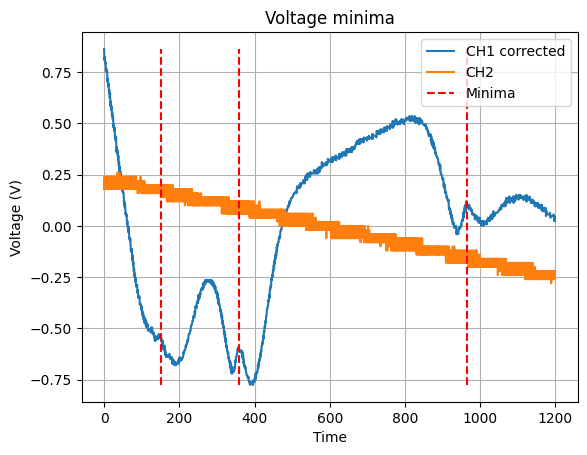

In [24]:
# plot
plot_channel(x_df, ch1_corrected_df, ch2, label1='CH1 corrected', label2='CH2', title='Voltage minima')
plt.vlines(x_df[minima_indices_df], ymin=np.min(ch1_corrected_df), ymax=np.max(ch1_corrected_df), color='r', linestyle='--', label='Minima')
plt.xlabel('Time')
plt.ylabel('Voltage (V)')
plt.legend()
plt.grid(True)
plt.show()

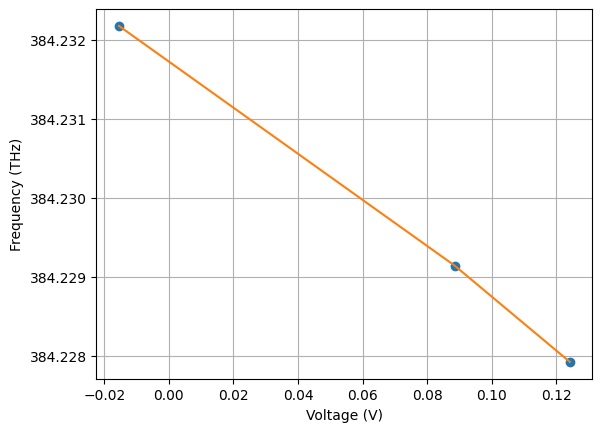

Slope method 2: -0.024159067781568812


In [32]:
# Fit frequency to voltage
calibration_func_df = fit_freq_to_voltage(f_peaks[:-1], peak_voltages_df, deg=2)

plt.plot(peak_voltages_df, f_peaks[:-1], 'o', label='Data points')
plt.plot(peak_voltages_df, calibration_func_df(peak_voltages_df), label='Polynomial fit')
plt.ticklabel_format(axis='y', style='plain', useOffset=False)
plt.xlabel('Voltage (V)')   
plt.ylabel('Frequency (THz)')
plt.grid(True)
plt.show()

# print("Slope:", poly_coeffs[0])
print("Slope method 2:", (f_peaks[-1] - f_peaks[0]) / (peak_voltages[-1] - peak_voltages[0]))

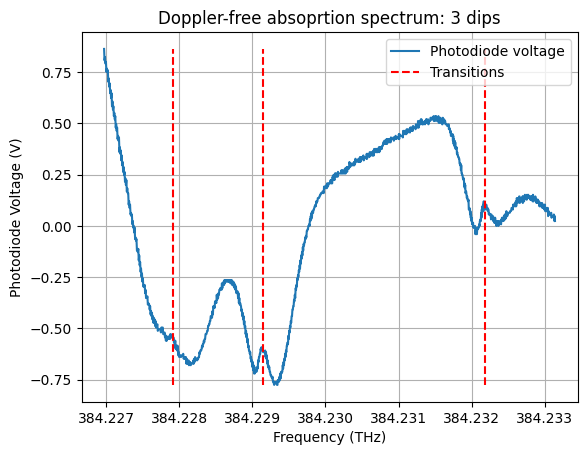

In [40]:
f_range_df = calibration_func_df(voltage_df)

plot_channel(f_range_df, ch1_corrected_df, label1='Photodiode voltage', title='Doppler-free absoprtion spectrum: 3 dips')
plt.vlines(f_peaks[:-1], ymin=np.min(ch1_corrected_df), ymax=np.max(ch1_corrected_df), color='r', linestyle='--', label='Transitions')
plt.ticklabel_format(axis='x', style='plain', useOffset=False)
plt.xlabel('Frequency (THz)')
plt.ylabel('Photodiode Voltage (V)')
plt.legend()
plt.grid(True)
plt.show()

### 4.) Calculate for each Doppler profile, the temperature of the atoms and the most probable atomic velocity and list them, including the theoretical values. Please compare and discuss your results !

In [27]:
masses = np.array([87, 85, 85, 87]) * const.m_u  # Convert atomic mass units to kg
FWHMs = np.array([580.55e6, 802.74e6, 748.11e6, 616.38e6]) # Hz
f_peaksHz = [ f * 1e12 for f in f_peaks]


temps = [
    (FWHMs[i] / (2 * f_peaksHz[i]))**2 * (masses[i] * const.c**2) / (const.k * 2 * np.log(2)) 
    for i in range(4)
]

print(temps)

[387.1795771380703, 723.2357837735904, 628.1366802887783, 436.4302138683452]


### Identify and label in all measured saturated absorption Doppler free spectra the observed peaks as fine structure transitions and cross-overs, as far as possible.

NameError: name 'p' is not defined

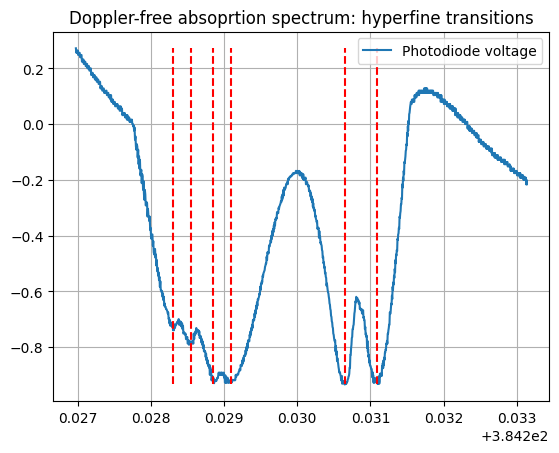

In [ ]:
x_df, ch1_corrected_df, ch2_df = load_data_remove_background('data\\NewFile13.csv', 'data\\NewFile18.csv')

hyperfine1 = [384.2283, 384.22854, 384.22885, 384.2291, 384.23065, 384.23109]

plot_channel(f_range_df, ch1_corrected_df, label1='Photodiode voltage', title='Doppler-free absoprtion spectrum: hyperfine transitions')
plt.vlines(hyperfine1, ymin=np.min(ch1_corrected_df), ymax=np.max(ch1_corrected_df), color='r', linestyle='--', label='hyperfine transitions')
plt.ticklabel_format(axis='x', style='plain', useOffset=False)
plt.xlabel('Frequency (THz)')
plt.ylabel('Photodiode Voltage (V)')
plt.legend()
plt.grid(True)
plt.show()